In [8]:
import pandas as pd
import geopandas as gpd

In [9]:
oak_parcels = gpd.read_parquet("../data/processed/oak_parcels.parquet")

In [10]:
#set to geographic coordinate system WGS 84 (ESPG 4326) which uses latitude and longitude
oak_parcels_4326 = oak_parcels.to_crs(epsg=4326)

zone_scale_map = oak_parcels_4326.explore(
    column='group_scale',
    categorical=True,
    cmap='Blues',
    missing_kwds={
        'color': '#d3d3d3',          #light grey for non-residential parcels
        'label': 'Non-Residential'   #for anything non-residential, label it as such
    },
    legend_kwds={'caption': 'Group Scale (1-6)'}
)

In [16]:
#zone_scale_map.save("visualizations/zone_scale_map.html")

In [11]:
colors = {
    #residential - blue
    "residential": "#06B6D4",

    #mixed-use - purple
    "mixed_use": "#8B5CF6",

    #commercial - orange
    "commercial": "#F97316",

    #industrial - red
    "industrial": "#DC2626",

    #parks and civic land - green
    "park": "#D9F99D",
    "civic": "#14B8A6",

    #unkown and NaN - grey
    "unknown": "#9CA3AF",
    "NaN": "#D1D5DB"
}

In [12]:
zone_type_map = oak_parcels_4326.explore(
    column="type",
    categorical=True,
    categories=list(colors.keys()),
    cmap=list(colors.values()),
    legend=True,
    tooltip=["type", 'input_label', 'zoning_description'],
    style_kwds={"fillOpacity": 0.8, "weight": 0.2}
)

In [13]:
#zone_type_map.save("visualizations/zone_type_map.html")

In [14]:
#ensure projected to crs in feet
#set to 2227: NAD83 / California zone 3 (US survey foot)
oak_parcels = oak_parcels.to_crs(epsg=2227)

#
oak_parcels["sqft"] = oak_parcels.area

# Summarize land use
zoning_summary = (
    oak_parcels.groupby("type")
    .agg(
        parcel_count=("type", "size"),
        total_sqft=("sqft", "sum")
    )
    .reset_index()
)

# Calculate percentage of total parcel area
zoning_summary["land_pct"] = (
    zoning_summary["total_sqft"]
    / zoning_summary["total_sqft"].sum()
    * 100
)

zoning_summary

,type,parcel_count,total_sqft,land_pct
0,civic,25,4.139215e+06,0.887749
1,commercial,1610,5.820221e+07,12.482796
2,industrial,481,4.251349e+07,9.117991
3,mixed_use,8158,1.977735e+08,42.417061
4,park,136,1.759245e+07,3.773104
5,residential,25464,1.460218e+08,31.317727
6,unknown,4,1.664743e+04,0.003570


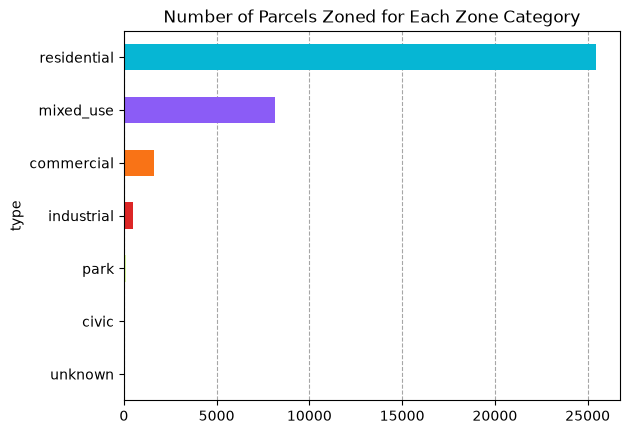

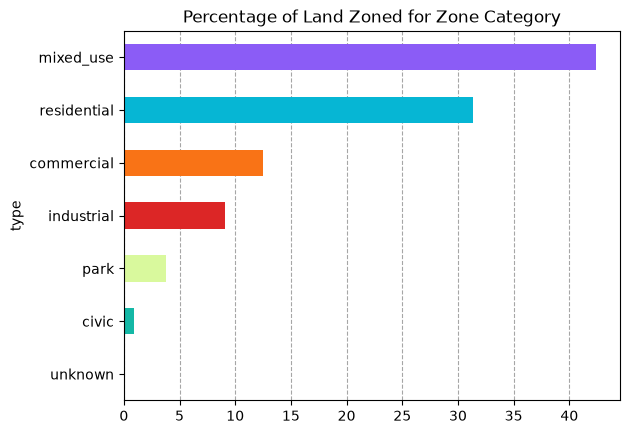

In [15]:
bar_colors = zoning_summary['type'].map(colors).fillna('#888888')

#plot parcel counts
count_summary_sorted = zoning_summary.sort_values(by='parcel_count', ascending=True)
zone_parcel_chart = count_summary_sorted.plot.barh(
    x='type',
    y='parcel_count',
    color=count_summary_sorted['type'].map(colors).fillna('#888888'),
    legend=False,
    title='Number of Parcels Zoned for Each Zone Category'
)

#plot the percentage of land
pct_summary_sorted = zoning_summary.sort_values(by='land_pct', ascending=True)
zone_land_chart = pct_summary_sorted.plot.barh(
    x='type',
    y='land_pct',
    color=pct_summary_sorted['type'].map(colors).fillna('#888888'),
    legend=False,
    title='Percentage of Land Zoned for Zone Category'
)

zone_parcel_chart.set_axisbelow(True)
zone_parcel_chart.grid(axis='x', linestyle='--', alpha=0.7, color='gray')
zone_land_chart.set_axisbelow(True)
zone_land_chart.grid(axis='x', linestyle='--', alpha=0.7, color='gray')

In [ ]:
#zone_parcel_chart.get_figure(
#).savefig("../visualizations/zoning_parcel_count_chart.jpg", dpi=300, bbox_inches="tight")
#zone_land_chart.get_figure(
#).savefig("../visualizations/zoning_land_pct_chart.jpg", dpi=300, bbox_inches="tight")